This notebook creates the input files of the sensitivity scenarios `sen_sc_*` (exogenous electrolyser capacity scaled to 50 % of the base value, year-dependent upper bound on heat pumps) and analyses their effect.

## 1. Capacity of electrolyzers, electric boilers and heat pumps per country in 2030 and 2035
`G_CAP_YCRAF` (GW) from the unrestricted run. `TECHGROUPKPOT` limits exogenous capacity (minus decommissioning) plus the accumulated new investments, so the table gives both: the **new** capacity (`ENDOGENOUS`, accumulated up to that year, not only built in that year) and the **total installed** capacity (`EXOGENOUS` + `ENDOGENOUS` + `DECOMMISSIONING`), which is the quantity the cap would bind.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
import pandas as pd
from IPython.display import display
from pybalmorel import MainResults

RUN_FOLDER = "base_dc"                                   # unrestricted run whose investments are used as reference
RESULTS    = "MainResults_fullweek.gdx"
YEARS      = ["2030", "2035"]
RENAME = {"Y": "Year", "C": "Country", "RRR": "Region", "AAA": "Area", "G": "Generation", "FFF": "Fuel",
          "TECH_TYPE": "Technology", "COMMODITY": "Commodity", "UNITS": "Unit"}

res = MainResults(files=RESULTS, paths=str(Path.cwd() / RUN_FOLDER / "model"), scenario_names=[RUN_FOLDER])

def p2x_technology(generation):
    """Technology of interest from the generator name (GNR_ELYS_*, GNR_HP_*, GNR_BO_ELEC_*); None for everything else."""
    g = str(generation).upper()
    if g.startswith("GNR_ELYS"): return "Electrolyzer"
    if g.startswith("GNR_HP_"): return "Heat pump"
    if g.startswith("GNR_BO_ELEC"): return "Electric boiler"
    return None

cap = res.get_result("G_CAP_YCRAF").rename(columns=RENAME)
print("Columns:", list(cap.columns))
# the column holding the variable type (EXOGENOUS / ENDOGENOUS / DECOMMISSIONING) is named differently across pybalmorel versions: find it by its values
var_col = next(c for c in cap.columns if cap[c].isin(["ENDOGENOUS"]).any())
cap = cap.rename(columns={var_col: "Variable"})
cap = cap.assign(Year=cap["Year"].astype(str), Tech=cap["Generation"].map(p2x_technology))
cap = cap.loc[cap["Tech"].notna() & cap["Year"].isin(YEARS)]
print("Variable types:", sorted(cap["Variable"].unique()))   # expected: DECOMMISSIONING, ENDOGENOUS, EXOGENOUS

by_var = cap.groupby(["Country", "Tech", "Year", "Variable"])["Value"].sum().unstack("Variable", fill_value=0)
table = pd.DataFrame({"New (accumulated)": by_var.get("ENDOGENOUS", 0),
                      "Total installed": by_var.sum(axis=1)}).unstack("Year").swaplevel(axis=1).sort_index(axis=1)
table = table.reindex(columns=pd.MultiIndex.from_product([YEARS, ["New (accumulated)", "Total installed"]]), fill_value=0)

# One table per technology (rows = countries, columns = year x quantity), GW
new_capacity = {tech: table.xs(tech, level="Tech") for tech in table.index.get_level_values("Tech").unique()}
for tech, t in new_capacity.items():
    t = t.copy(); t.loc["Total"] = t.sum()
    print(f"{tech}: installed capacity per country (GW)")
    display(t.round(3))


Loading /work3/s243704/Balmorel/base_dc/model/MainResults_fullweek.gdx
Columns: ['Scenario', 'Year', 'Country', 'Region', 'Area', 'Generation', 'Fuel', 'Commodity', 'Technology', 'Category', 'Unit', 'Value']
Variable types: ['DECOMMISSIONING', 'ENDOGENOUS', 'EXOGENOUS']
Electric boiler: installed capacity per country (GW)


2030                              2035  \
                       New (accumulated) Total installed New (accumulated)   
Country                                                                      
ALBANIA                            0.181           0.242             0.181   
AUSTRIA                            1.591           1.869             1.591   
BELGIUM                            0.730           2.078             0.805   
BOSNIA_AND_HERZEGOVINA             0.100           0.116             0.100   
BULGARIA                           1.671           1.779             1.704   
CROATIA                            0.293           0.884             0.417   
CYPRUS                             0.346           0.449             0.346   
CZECH_REPUBLIC                     0.627           0.894             0.679   
DENMARK                            0.671           0.952             0.600   
ESTONIA                            0.057           0.277             0.057   
FINLAND                            6.209           7.205             6.237   
FRANCE                             7.412          18.099             4.048   
GERMANY                           23.786          29.972            19.444   
GREECE                             2.956           4.498             3.073   
HUNGARY                            1.256           1.388             1.349   
IRELAND                            2.257           2.545             1.421   
ITALY                              8.468          18.809             8.468   
LATVIA                             0.000           0.118             0.000   
LITHUANIA                          0.418           0.546             0.197   
LUXEMBOURG                         0.501           0.553             0.477   
MALTA                              0.054           0.086             0.054   
MONTENEGRO                         0.049           0.069             0.049   
NETHERLANDS                        2.250           3.124             2.318   
NORTH_MACEDONIA                    0.222           0.272             0.222   
NORWAY                             0.584           2.636             0.630   
POLAND                            14.486          15.384            13.127   
PORTUGAL                           1.101           2.468             2.014   
ROMANIA                            2.477           2.747             3.259   
SERBIA                             0.724           0.776             0.776   
SLOVAKIA                           0.924           1.023             1.180   
SLOVENIA                           0.611           0.645             0.611   
SPAIN                              6.596          14.461             8.472   
SWEDEN                             6.555           8.070             4.561   
SWITZERLAND                        0.433           0.665             0.512   
UNITED_KINGDOM                     6.070          10.695             6.070   
Total                            102.665         156.394            95.050   

                                        
                       Total installed  
Country                                 
ALBANIA                          0.214  
AUSTRIA                          1.743  
BELGIUM                          1.541  
BOSNIA_AND_HERZEGOVINA           0.109  
BULGARIA                         1.762  
CROATIA                          0.740  
CYPRUS                           0.402  
CZECH_REPUBLIC                   0.825  
DENMARK                          0.742  
ESTONIA                          0.177  
FINLAND                          6.780  
FRANCE                           9.878  
GERMANY                         22.818  
GREECE                           3.914  
HUNGARY                          1.421  
IRELAND                          1.577  
ITALY                           14.108  
LATVIA                           0.064  
LITHUANIA                        0.275  
LUXEMBOURG                       0.505  
MALTA                            0.085  
MONTENEGR

Heat pump: installed capacity per country (GW)


2030                              2035  \
                       New (accumulated) Total installed New (accumulated)   
Country                                                                      
ALBANIA                            0.812           0.814             0.846   
AUSTRIA                           20.681          20.682            20.916   
BELGIUM                           22.001          22.001            23.053   
BOSNIA_AND_HERZEGOVINA             1.881           1.881             1.950   
BULGARIA                           6.025           6.026             6.413   
CROATIA                            5.398           5.411             5.589   
CYPRUS                             0.534           0.536             0.590   
CZECH_REPUBLIC                    17.830          17.832            18.543   
DENMARK                            9.794           9.834            10.390   
ESTONIA                            2.151           2.151             2.191   
FINLAND                           15.894          18.022            17.262   
FRANCE                            95.328          95.537            97.420   
GERMANY                          149.400         150.118           160.623   
GREECE                             8.907           8.941             9.738   
HUNGARY                           18.822          18.823            19.373   
IRELAND                            7.796           7.808             8.558   
ITALY                             83.273          83.457            87.490   
LATVIA                             2.693           2.693             2.749   
LITHUANIA                          3.603           3.603             3.648   
LUXEMBOURG                         1.842           1.842             1.935   
MALTA                              0.210           0.212             0.235   
MONTENEGRO                         0.244           0.244             0.258   
NETHERLANDS                       25.414          25.414            26.282   
NORTH_MACEDONIA                    0.603           0.604             0.631   
NORWAY                             5.854           6.296             6.330   
POLAND                            38.920          38.924            41.228   
PORTUGAL                           5.129           5.161             5.408   
ROMANIA                           18.988          18.990            19.819   
SERBIA                             3.996           3.997             4.193   
SLOVAKIA                           7.695           7.696             8.152   
SLOVENIA                           3.039           3.039             3.138   
SPAIN                             31.501          31.648            35.469   
SWEDEN                            15.133          16.881            16.353   
SWITZERLAND                       16.197          16.197            16.437   
UNITED_KINGDOM                    93.242          93.412            96.699   
Total                            740.833         746.727           779.906   

                                        
                       Total installed  
Country                                 
ALBANIA                          0.847  
AUSTRIA                         20.917  
BELGIUM                         23.053  
BOSNIA_AND_HERZEGOVINA           1.950  
BULGARIA                         6.414  
CROATIA                          5.597  
CYPRUS                           0.591  
CZECH_REPUBLIC                  18.543  
DENMARK                         10.419  
ESTONIA                          2.191  
FINLAND                         18.441  
FRANCE                          97.534  
GERMANY                        161.014  
GREECE                           9.756  
HUNGARY                         19.373  
IRELAND                          8.564  
ITALY                           87.591  
LATVIA                           2.749  
LITHUANIA                        3.648  
LUXEMBOURG                       1.935  
MALTA                            0.236  
MONTENEGR

Electrolyzer: installed capacity per country (GW)


2030                              2035  \
               New (accumulated) Total installed New (accumulated)   
Country                                                              
AUSTRIA                    0.000           1.000             0.000   
BELGIUM                    0.000           0.000             0.000   
DENMARK                    0.000           5.652             0.000   
ESTONIA                    0.002           0.002             0.002   
FINLAND                    0.353           0.353             0.353   
FRANCE                     0.000           6.500             0.000   
GERMANY                    0.056           6.554             0.056   
ITALY                      0.000           5.000             0.000   
LATVIA                     0.002           0.002             0.002   
LITHUANIA                  0.198           0.198             0.198   
NETHERLANDS                0.000           3.500             0.000   
NORWAY                     0.194           0.194             0.194   
POLAND                     1.078           3.078             1.718   
PORTUGAL                   0.000           2.300             0.000   
SPAIN                      0.000           4.000             0.000   
SWEDEN                     0.000           1.860             0.000   
SWITZERLAND                0.001           0.001             0.001   
UNITED_KINGDOM             0.034           0.034             0.034   
Total                      1.919          40.229             2.559   

                                
               Total installed  
Country                         
AUSTRIA                  1.000  
BELGIUM                  0.000  
DENMARK                  6.499  
ESTONIA                  0.002  
FINLAND                  0.353  
FRANCE                   6.500  
GERMANY                  6.554  
ITALY                    5.000  
LATVIA                   0.002  
LITHUANIA                0.198  
NETHERLANDS              3.500  
NORWAY                   0.194  
POLAND                   3.718  
PORTUGAL                 2.300  
SPAIN                    4.000  
SWEDEN                   1.961  
SWITZERLAND              0.001  
UNITED_KINGDOM           0.034  
Total                   41.817

## 2. Inputs of the sensitivity scenarios
The three `sen_sc_*` scenarios differ from their base scenarios in two input files, both written into the `data/` folder of each scenario:
- **Electrolysers (2.0)**: the **exogenous capacity** of the electrolysers is set to `ELY_EXO_SHARE` (50 %) of the value in the base scenario for every country from 2030 on. This is done on the input itself: a scenario-specific `HYDROGEN_GKFX.inc` is a copy of `base/data/HYDROGEN_GKFX.inc` with one added statement that halves the exogenous electrolyser capacity (`GKFX`) from 2030 on. The model reads the file of the scenario folder before the one in `base/data`. Investments in new electrolysers are not restricted.
- **Heat pumps (2.1)**: a year-dependent upper bound `TECHGROUPKPOT_Y.inc` of 75 % of the new capacity of `base_nodc` (needs the optional parameter `TECHGROUPKPOT_Y` added to `base/model`).

`TECHGROUPKPOT` (no year index; it limits exogenous plus new capacity together) is therefore **not** used for electrolysers any more. The cell below reads the model variables of the reference run and resets `TECHGROUPKPOT.inc` of the scenario folders to the model default (copy of `base/data/TECHGROUPKPOT.inc`), so that no earlier limit stays in force. The files `TECH_GROUP.inc`, `TECH_GROUP_VALUE.inc` and `HYDROGEN_GDATA.inc` that were written for the earlier `TECHGROUPKPOT` limit on electrolysers are not needed any more and can be deleted from the scenario folders; they are harmless if kept.

In [ ]:
SHARE = 0.5                                              # new capacity allowed, as share of the new capacity in the unrestricted run
SENS_SCENARIOS = ["sen_sc_base_dc", "sen_sc_base_nodc", "sen_sc_Flex_1_share100_cap125_12h"]      # scenario folders in the repository root; the model reads their data/ before base/data/
SENS_DIRS = [Path.cwd() / name / "data" for name in SENS_SCENARIOS]       # the files are written directly into the data/ folder of each scenario
missing_dirs = [str(d) for d in SENS_DIRS if not d.exists()]
if missing_dirs:                                                           # do not create new folders by accident (e.g. a mistyped name)
    raise FileNotFoundError("Scenario data folder(s) not found: " + ", ".join(missing_dirs))
BASE_FILE = Path.cwd() / "base" / "data" / "TECHGROUPKPOT.inc"
TECH_GROUP_OF = {"Electrolyzer": "ELECTROLYZER", "Heat pump": "HEATPUMP"}

FIRST_YEAR = "2025"                                       # not restricted: its investments stay under the cap
CAP_YEARS = YEARS                                         # years in which new capacity is restricted
ENDOFMODEL = "all_endofmodel_fullweek.gdx"                # raw model gdx of the reference run (model units)

# The cap must be in the units of the model equation (QKTECHGROUPR): GKFX - VDECOM_EXO_ACCUM + VGKNACCUMNET. G_CAP_YCRAF is rescaled
# (electrolyzers: hydrogen output instead of electricity input, so it is a factor 1/efficiency lower), so the raw variables are read.
import gams.transfer as gt
container = gt.Container()
container.read(str(Path.cwd() / RUN_FOLDER / "model" / ENDOFMODEL), symbols=["GKFX", "VDECOM_EXO_ACCUM", "VGKNACCUMNET"])
area_region = res.get_result("G_CAP_YCRAF").rename(columns=RENAME)[["Area", "Region"]].drop_duplicates().set_index("Area")["Region"]

def p2x_group(generation):
    """Capped TECH_GROUP of the generator. GNR_IMPORT_H2 is also in the group ELECTROLYZER in GDATA, but it is moved to BACKUP_HYDROGEN below, so it is not capped."""
    g = str(generation).upper()
    if g.startswith("GNR_ELYS"): return "ELECTROLYZER"
    if g.startswith("GNR_HP_"): return "HEATPUMP"
    return None

def model_var(name, column):
    t = container[name].records.rename(columns={container[name].records.columns[0]: "Year", container[name].records.columns[1]: "Area",
                                               container[name].records.columns[2]: "Generation"})
    t = t.assign(Year=t["Year"].astype(str), Region=t["Area"].map(area_region), Tech=t["Generation"].map(p2x_group))
    t = t.loc[t["Tech"].isin(["ELECTROLYZER", "HEATPUMP"]) & t["Year"].isin([FIRST_YEAR] + CAP_YEARS) & t["Region"].notna()]
    return t.groupby(["Region", "Tech", "Year"])[column].sum()

gkfx = model_var("GKFX", "value")                         # exogenous capacity (MW)
decom = model_var("VDECOM_EXO_ACCUM", "level")            # accumulated decommissioning of exogenous capacity (MW)
endo = model_var("VGKNACCUMNET", "level").unstack("Year", fill_value=0)      # accumulated new investments (MW)
# The electrolysers are no longer limited through TECHGROUPKPOT: their exogenous capacity is scaled in section 2.0. MARGIN_MW is the safety margin of the
# heat pump bound of section 2.1 (a bound exactly equal to the existing capacity is infeasible because of rounding and solver tolerances in GKFX - VDECOM_EXO_ACCUM).
MARGIN_MW = 1.0

# Reset TECHGROUPKPOT.inc of the scenario folders to the model default, so that an earlier electrolyser / heat pump limit does not stay in force.
default_techgroupkpot = BASE_FILE.read_bytes()
for sens_dir in SENS_DIRS:
    sens_dir.mkdir(parents=True, exist_ok=True)
    (sens_dir / "TECHGROUPKPOT.inc").write_bytes(default_techgroupkpot)
    print(f"Written {sens_dir / 'TECHGROUPKPOT.inc'} (copy of the model default: no limit on electrolysers or heat pumps)")

Written /work3/s243704/Balmorel/Sensitivities/sc_base_dc/data/TECHGROUPKPOT.inc
Written /work3/s243704/Balmorel/Sensitivities/sc_base_dc/data/TECH_GROUP.inc
Written /work3/s243704/Balmorel/Sensitivities/sc_base_dc/data/TECH_GROUP_VALUE.inc
Written /work3/s243704/Balmorel/Sensitivities/sc_base_dc/data/HYDROGEN_GDATA.inc
Written /work3/s243704/Balmorel/Sensitivities/sc_base_nodc/data/TECHGROUPKPOT.inc
Written /work3/s243704/Balmorel/Sensitivities/sc_base_nodc/data/TECH_GROUP.inc
Written /work3/s243704/Balmorel/Sensitivities/sc_base_nodc/data/TECH_GROUP_VALUE.inc
Written /work3/s243704/Balmorel/Sensitivities/sc_base_nodc/data/HYDROGEN_GDATA.inc
Written /work3/s243704/Balmorel/Sensitivities/sc_Flex_1_share100_cap125_12h/data/TECHGROUPKPOT.inc
Written /work3/s243704/Balmorel/Sensitivities/sc_Flex_1_share100_cap125_12h/data/TECH_GROUP.inc
Written /work3/s243704/Balmorel/Sensitivities/sc_Flex_1_share100_cap125_12h/data/TECH_GROUP_VALUE.inc
Written /work3/s243704/Balmorel/Sensitivities/sc_Flex

Tech,ELECTROLYZER,HEATPUMP
Region,,
AL,0.0,799.6
AT,1526.1,20272.9
BA,0.0,1850.0
BE,0.0,0.0
BG,0.0,5948.2
CH,0.0,15920.0
CY,0.0,523.5
CZ,0.0,17618.4
DE4-E,3038.9,24156.7


### 2.0 Exogenous electrolyser capacity: HYDROGEN_GKFX.inc with one added line (50 % from 2030 on)
Writes `HYDROGEN_GKFX.inc` into the `data/` folder of every scenario in `SENS_DIRS`. The file is an unchanged copy of `base/data/HYDROGEN_GKFX.inc` with **one statement added at the end**, after the table has been merged into `GKFX`:

`GKFX(YYY,AAA,'GNR_ELYS_ELEC_AEC_Y-2020')$(YYY.VAL GE 2030) = 0.5 * GKFX(YYY,AAA,'GNR_ELYS_ELEC_AEC_Y-2020');`

It multiplies the exogenous electrolyser capacity of every area (so every country) by `ELY_EXO_SHARE` in every year from `SCALE_FROM_YEAR` (2030) on; earlier years and all other generators are unchanged. The table values themselves stay as in the base file. The model reads the file of the scenario folder before the one in `base/data` (`base_dc` and `base_nodc` have no `HYDROGEN_GKFX.inc` of their own). Investments in new electrolysers are not restricted.

Note on the input data: the base table has 23.0 GW in 2025, **blank (= 0) in 2026-2029** and 66.8 GW from 2030 (announced 2030 targets, 1/3 of them in 2025). With the added line this is 23.0 GW in 2025 and 33.4 GW from 2030.

In [ ]:
# 2.0 Exogenous electrolyser capacity of the sen_sc scenarios: HYDROGEN_GKFX.inc = the base file + one line that scales the electrolysers from SCALE_FROM_YEAR on
import re
ELY_EXO_SHARE = 0.5
SCALE_FROM_YEAR = 2030

def read_elys_gkfx(path):
    """Exogenous electrolyser capacity (rows GNR_ELYS* of a HYDROGEN_GKFX.inc) as region x year (MW), including statements of the form
    GKFX(YYY,AAA,'GNR_ELYS...')$(YYY.VAL GE year) = factor * GKFX(...) that the file may contain at its end.
    The GAMS table is position based: every number is assigned to the year header that it stands under."""
    text = Path(path).read_bytes().decode("latin-1")
    lines = text.split("\n")
    header_idx = [i for i, l in enumerate(lines) if re.match(r"^\s*2012\s", l)]
    cap = {}
    for i, l in enumerate(lines):
        if "GNR_ELYS" in l and not l.lstrip().startswith("*") and "GKFX(" not in l:
            h = max(k for k in header_idx if k < i)
            years = [(m.group(0), m.start()) for m in re.finditer(r"\S+", lines[h])]
            toks = [(m.group(0), m.start()) for m in re.finditer(r"\S+", l.rstrip("\r"))]
            k = [j for j, (x, _) in enumerate(toks) if x == "."][0]
            region = area_region.get(toks[0][0], toks[0][0])
            for x, pos in toks[k + 2:]:
                year = min(years, key=lambda q: abs(q[1] - pos))[0]
                cap.setdefault(region, {})[year] = cap.get(region, {}).get(year, 0.0) + float(x)
    table = pd.DataFrame(cap).T.fillna(0.0)
    for m in re.finditer(r"^GKFX\(YYY,AAA,'GNR_ELYS[^']*'\)\$\(YYY\.VAL GE (\d+)\)\s*=\s*([0-9.]+)\s*\*", text, flags=re.M):
        table.loc[:, [y for y in table.columns if int(y) >= int(m.group(1))]] *= float(m.group(2))
    return table

base_gkfx_file = Path.cwd() / "base" / "data" / "HYDROGEN_GKFX.inc"
base_text = base_gkfx_file.read_bytes().decode("latin-1")
ely_generators = sorted(set(re.findall(r"GNR_ELYS\S*", "\n".join(l for l in base_text.split("\n") if not l.lstrip().startswith("*")))))
added = ["", f"* Sensitivity: exogenous electrolyser capacity from {SCALE_FROM_YEAR} on = {ELY_EXO_SHARE:.0%} of the base value (every area and every year)"] + \
        [f"GKFX(YYY,AAA,'{g}')$(YYY.VAL GE {SCALE_FROM_YEAR}) = {ELY_EXO_SHARE} * GKFX(YYY,AAA,'{g}');" for g in ely_generators]
new_text = base_text.rstrip() + "\n" + "\n".join(added) + "\n"
for sens_dir in SENS_DIRS:
    sens_dir.mkdir(parents=True, exist_ok=True)
    (sens_dir / "HYDROGEN_GKFX.inc").write_bytes(new_text.encode("latin-1"))
    print(f"Written {sens_dir / 'HYDROGEN_GKFX.inc'}")
print("Added at the end of the file:"); print("\n".join(added[1:]))

# Check: read the base file and the written file back, total over Europe (GW)
check_years = ["2025", "2026", "2030", "2035"]
chk = pd.DataFrame({"base": read_elys_gkfx(base_gkfx_file).sum() / 1e3, "sen_sc (written)": read_elys_gkfx(SENS_DIRS[0] / "HYDROGEN_GKFX.inc").sum() / 1e3}).reindex(check_years).fillna(0)
chk["sen_sc / base (%)"] = chk["sen_sc (written)"] / chk["base"].replace(0, float("nan")) * 100
display(chk.round(2))

### 2.1 Year-dependent upper bound on heat pumps: TECHGROUPKPOT_Y.inc
`TECHGROUPKPOT` has no year index, so a limit that differs per modelled year needs the optional year-indexed parameter `TECHGROUPKPOT_Y(year, region, technology group)` that was added to the model (`base/model/bb4datainc.inc` and equation `QKTECHGROUPR_Y` in `base/model/Balmorelbb4.inc`). It is only active in scenarios that have a `data/TECHGROUPKPOT_Y.inc`; all other scenarios are unchanged.

The limit for the group `HEATPUMP` in each region and year is, in the units of the model equation (MW),
`exogenous capacity of HP_REF_FOLDER net of decommissioning + HP_SHARE x new capacity of HP_REF_FOLDER`
for that year (`HP_REF_FOLDER` = `base_nodc`, `HP_SHARE` = 75 %), i.e. the investment in heat pumps is at most 75 % of what the unrestricted `base_nodc` invests in the same year. Because the constraint counts exogenous plus new capacity together, the exogenous part of the reference is added so that only the new capacity is reduced. Regions where `base_nodc` has no heat pumps get `EPS` (= 0 MW). The same file is written for all scenarios in `SENS_DIRS`, so they all get the same limit. The heat pump column is no longer written to `TECHGROUPKPOT.inc` (cell above).

In [ ]:
# 2.1 Year-dependent upper bound on heat pumps (TECHGROUPKPOT_Y.inc): HP_SHARE of the new heat pump capacity of base_nodc in each year
HP_SHARE = 0.75
HP_REF_FOLDER = "base_nodc"                                # the reference whose investments are scaled; all SENS_DIRS get the same file
HP_YEARS = [FIRST_YEAR] + CAP_YEARS                        # every modelled year

hp_ref = gt.Container()
hp_ref.read(str(Path.cwd() / HP_REF_FOLDER / "model" / ENDOFMODEL), symbols=["GKFX", "VDECOM_EXO_ACCUM", "VGKNACCUMNET"])

def hp_by_region_year(name, column):
    """Heat pump capacity (generators GNR_HP_*) per region and modelled year in the reference run (MW, raw model variable)."""
    r = hp_ref[name].records
    r = r.rename(columns={r.columns[0]: "Year", r.columns[1]: "Area", r.columns[2]: "Generation"})
    r = r.assign(Year=r["Year"].astype(str), Region=r["Area"].map(area_region))
    r = r.loc[r["Generation"].astype(str).str.upper().str.startswith("GNR_HP_") & r["Year"].isin(HP_YEARS) & r["Region"].notna()]
    return r.groupby(["Region", "Year"])[column].sum().unstack("Year", fill_value=0).reindex(columns=HP_YEARS, fill_value=0)

regions = sorted(area_region.dropna().unique())
hp_exo = hp_by_region_year("GKFX", "value").sub(hp_by_region_year("VDECOM_EXO_ACCUM", "level"), fill_value=0).clip(lower=0)   # exogenous net of decommissioning
hp_new = hp_by_region_year("VGKNACCUMNET", "level")                                                                           # accumulated new capacity
hp_cap = hp_exo.add(HP_SHARE * hp_new, fill_value=0).reindex(index=regions, columns=HP_YEARS).fillna(0)
hp_cap = (hp_cap + MARGIN_MW * (hp_cap > 0)).round(1)      # same safety margin as above; regions without heat pumps keep EPS (= 0 MW)

hp_lines = [f"* Year-dependent upper bound of the heat pump capacity (exogenous capacity net of decommissioning + new capacity), MW per region.",
            f"* {HP_SHARE:.0%} of the new heat pump capacity of {HP_REF_FOLDER} in each year, plus its exogenous capacity net of decommissioning."]
for region in regions:
    for year in HP_YEARS:
        v = hp_cap.loc[region, year]
        hp_lines.append(f"TECHGROUPKPOT_Y('{year}','{region}','HEATPUMP') = {'EPS' if v == 0 else format(v, '.1f')};")

for sens_dir in SENS_DIRS:
    sens_dir.mkdir(parents=True, exist_ok=True)
    (sens_dir / "TECHGROUPKPOT_Y.inc").write_text("\n".join(hp_lines) + "\n")
    print(f"Written {sens_dir / 'TECHGROUPKPOT_Y.inc'}")

summary_hp = pd.DataFrame({f"{HP_REF_FOLDER}: new (GW)": hp_new.sum() / 1e3, f"{HP_REF_FOLDER}: exogenous net (GW)": hp_exo.sum() / 1e3,
                           "Upper bound, exogenous + new (GW)": hp_cap.sum() / 1e3}).T
summary_hp.loc[f"Bound on new capacity (GW)"] = summary_hp.loc["Upper bound, exogenous + new (GW)"] - summary_hp.loc[f"{HP_REF_FOLDER}: exogenous net (GW)"]
display(summary_hp.round(1))

### 2.2 Installed heat pumps in base_nodc and the upper bound of the sensitivity scenarios
Installed heat pump capacity in Europe per modelled year in `base_nodc` (exogenous capacity net of decommissioning, light, plus accumulated new capacity, solid) next to the upper bound of section 2.1 on the same quantity (orange). The bound is the same in `sen_sc_base_nodc`, `sen_sc_base_dc` and the flexibility scenario. Uses `hp_exo`, `hp_new` and `hp_cap` of section 2.1 (run it first); raw model units, GW.

In [ ]:
# 2.2 Installed heat pumps in base_nodc vs the upper bound of the sensitivity scenarios (GW)
import numpy as np
import matplotlib.pyplot as plt
hp_plot = pd.DataFrame({"Exogenous, net": hp_exo.sum() / 1e3, "New": hp_new.sum() / 1e3, "Upper bound": hp_cap.sum() / 1e3}).reindex(HP_YEARS)
hp_plot["Installed"] = hp_plot["Exogenous, net"] + hp_plot["New"]
hp_plot["Bound / installed (%)"] = hp_plot["Upper bound"] / hp_plot["Installed"] * 100
display(hp_plot.round(1))

fig, ax = plt.subplots(figsize=(8, 4.8))
x = np.arange(len(HP_YEARS)); w = 0.5
ax.bar(x, hp_plot["Exogenous, net"], w, color="#a9c9ee", edgecolor="#fcfcfb", label="base_nodc: exogenous, net of decommissioning")
ax.bar(x, hp_plot["New"], w, bottom=hp_plot["Exogenous, net"], color="#2a78d6", edgecolor="#fcfcfb", label="base_nodc: new (accumulated)")
ax.plot(x, hp_plot["Upper bound"], color="#eb6834", linestyle="--", marker="D", linewidth=1.5, label="Upper bound in sen_sc_* (TECHGROUPKPOT_Y)")
for xi, inst, bound in zip(x, hp_plot["Installed"], hp_plot["Upper bound"]):
    ax.annotate(f"installed {inst:,.0f}", (xi, inst), ha="center", va="bottom", fontsize=8, xytext=(0, 4), textcoords="offset points")
    ax.annotate(f"bound {bound:,.0f}\n({bound / inst * 100:.0f} %)", (xi, bound), ha="left", va="top", fontsize=8, color="#c2410c", xytext=(8, -2), textcoords="offset points", bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
ax.set_xticks(x); ax.set_xticklabels(HP_YEARS); ax.margins(y=0.15)
ax.set_title("Heat pumps: installed capacity in base_nodc and the upper bound of the sensitivities", loc="left"); ax.set_ylabel("GW")
ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
for side in ("top", "right"): ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

### 2.3 Exogenous electrolyser capacity: base input and the input of the sen_sc scenarios
The exogenous electrolyser capacity that the model reads: `base/data/HYDROGEN_GKFX.inc` for the base scenarios and the `HYDROGEN_GKFX.inc` of each `sen_sc_*` folder (section 2.0), read **from the scenario folders**. Input data of the files: 23.0 GW in 2025, 0 in 2026-2029 and 66.8 GW from 2030 in the base; in the sen_sc scenarios the same with the added line applied (23.0 GW in 2025, 33.4 GW from 2030). (The model's decommissioning add-on works on this input; see sections 5 and 5.1 for what the model keeps.)
- **Left**: Europe in total in the modelled years.
- **Right**: the same per region in 2030 for the 12 regions with the most capacity.
Uses `read_elys_gkfx` of section 2.0; MW of electricity input, shown in GW.

In [ ]:
# 2.3 Exogenous electrolyser capacity: base input vs the HYDROGEN_GKFX.inc of the sen_sc scenarios (GW)
import numpy as np
import matplotlib.pyplot as plt

PLOT_YEARS = [FIRST_YEAR] + CAP_YEARS                                      # modelled years
base_ely = read_elys_gkfx(base_gkfx_file).reindex(columns=PLOT_YEARS).fillna(0)
sen_ely = {}
for name, data_dir in zip(SENS_SCENARIOS, SENS_DIRS):
    f = data_dir / "HYDROGEN_GKFX.inc"
    if f.exists(): sen_ely[name] = read_elys_gkfx(f).reindex(index=base_ely.index, columns=PLOT_YEARS).fillna(0)
    else: print(f"NOTE: {f} does not exist: run section 2.0; the scenario then reads the base file")
    print(f"{name}: {f}")

europe = pd.DataFrame({"base (base/data)": base_ely.sum() / 1e3, **{n: t.sum() / 1e3 for n, t in sen_ely.items()}})
display(europe.round(2))
display((europe.drop(columns="base (base/data)").div(europe["base (base/data)"], axis=0) * 100).round(1).rename(columns=lambda c: c + " / base (%)"))

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.3]})
x = np.arange(len(PLOT_YEARS))
same = len(sen_ely) > 1 and all(np.allclose(t.values, list(sen_ely.values())[0].values) for t in sen_ely.values())
plot_series = {"base": europe.iloc[:, 0]}
if same: plot_series["sen_sc scenarios (all identical)"] = europe.iloc[:, 1]
else: plot_series.update({n: europe[n] for n in sen_ely})
w = 0.8 / len(plot_series); colors = ["#9a9992", "#2a78d6", "#eb6834", "#1baf7a"]
for k, (label, ser) in enumerate(plot_series.items()):
    bars = ax.bar(x + (k - (len(plot_series) - 1) / 2) * w, ser.values, w, color=colors[k % 4], edgecolor="#fcfcfb", label=label)
    for b, v in zip(bars, ser.values): ax.annotate(f"{v:,.1f}", (b.get_x() + b.get_width() / 2, v), ha="center", va="bottom", fontsize=8, xytext=(0, 3), textcoords="offset points")
ax.set_xticks(x); ax.set_xticklabels(PLOT_YEARS); ax.margins(y=0.2)
ax.set_title("Europe", loc="left"); ax.set_ylabel("GW"); ax.legend(frameon=False, loc="upper left", fontsize=8)

year = CAP_YEARS[0]
top = base_ely[year].sort_values(ascending=False).head(12).index[::-1]
y = np.arange(len(top)); h = 0.38
ax2.barh(y + h / 2, base_ely.loc[top, year] / 1e3, h, color="#9a9992", edgecolor="#fcfcfb", label=f"base, {year}")
first = list(sen_ely)[0] if sen_ely else None
if first: ax2.barh(y - h / 2, sen_ely[first].loc[top, year] / 1e3, h, color="#2a78d6", edgecolor="#fcfcfb", label=f"{first}" + ("" if same else " (others differ)"))
ax2.set_yticks(y); ax2.set_yticklabels(top)
ax2.set_title(f"Top 12 regions, {year}", loc="left"); ax2.set_xlabel("GW"); ax2.legend(frameon=False, loc="lower right", fontsize=8)
for a in (ax, ax2):
    a.grid(axis="y" if a is ax else "x", alpha=0.3); a.set_axisbelow(True)
    for side in ("top", "right"): a.spines[side].set_visible(False)
fig.suptitle("Exogenous electrolyser capacity (input): base and the sen_sc scenarios", x=0.01, ha="left", fontsize=13)
plt.tight_layout(); plt.show()

## 3. The heat pump bound compared with the new installation in 2030 and 2035
For heat pumps: the room that the year-dependent bound of section 2.1 leaves for **new** capacity in each region and year, compared with the new capacity that the unrestricted run (`RUN_FOLDER`) installed (accumulated `VGKNACCUMNET`). (Electrolysers have no cap any more: their exogenous capacity is scaled in section 2.0.)
- **Bound on new capacity** = the bound `hp_cap` of section 2.1 (based on `base_nodc`) minus the existing capacity still running that year (`GKFX` - `VDECOM_EXO_ACCUM`). It is the most new capacity the constraint `QKTECHGROUPR_Y` allows in that year.
- **New installation** = accumulated new investments of the unrestricted run in that year, so it includes what was built before.
- Everything is read from the raw model variables (MW, model units), the same units as the bound. Where the bound is below the new installation, the bound binds and the difference is the investment that the sensitivity removes.

Totals over all countries (GW, model units)


New  Cap on new  Cap / new installation (%)  \
Tech         Year                                                   
ELECTROLYZER 2030    2.34        2.84                      121.38   
             2035    3.13        1.40                       44.74   
HEATPUMP     2030  740.83      666.03                       89.90   
             2035  779.91      668.78                       85.75   

                   Removed by the cap (GW)  
Tech         Year                           
ELECTROLYZER 2030                     0.00  
             2035                     1.73  
HEATPUMP     2030                    74.80  
             2035                   111.13

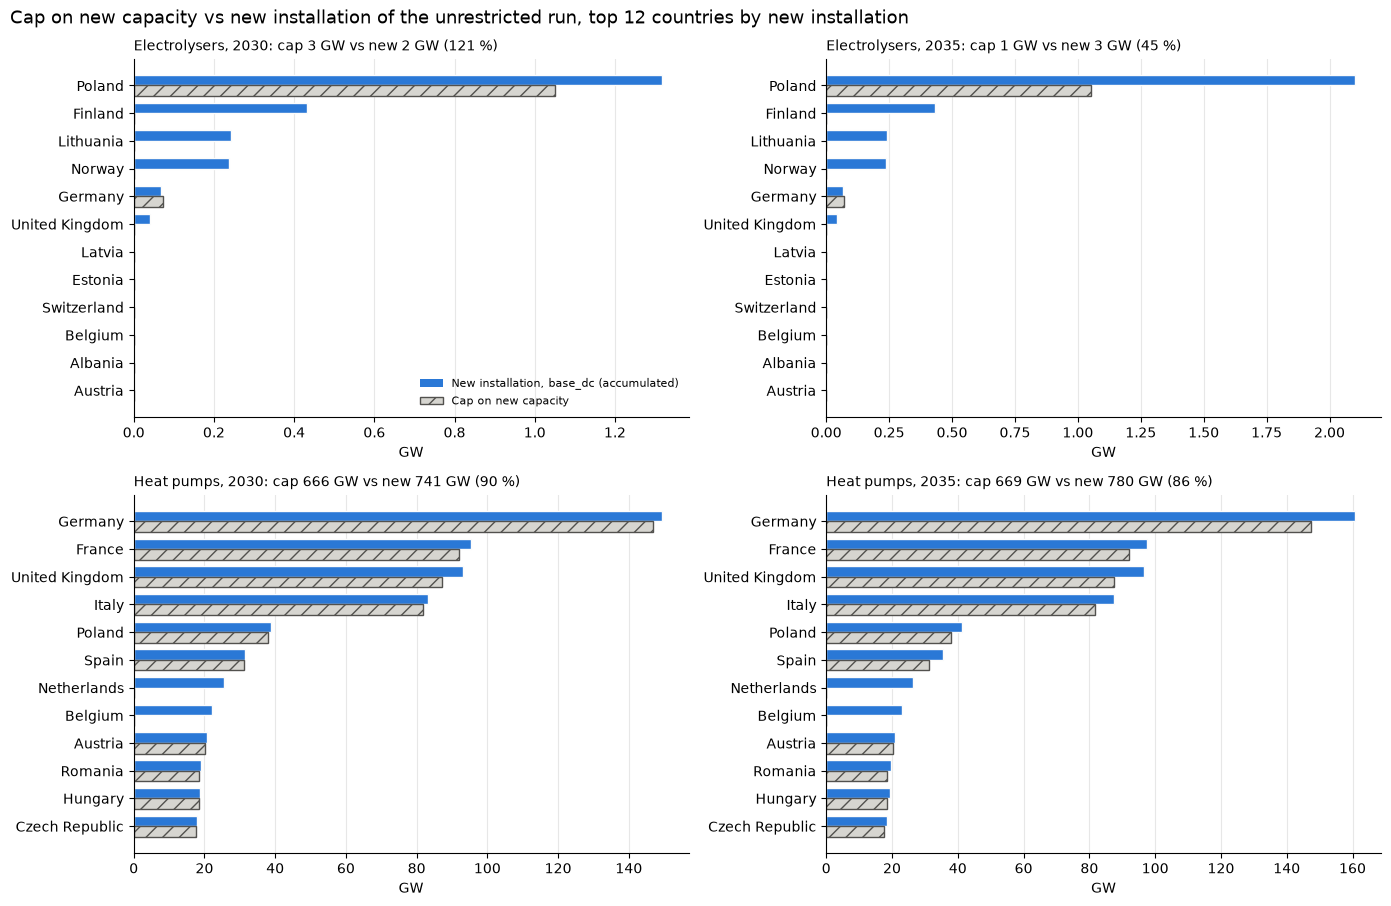

In [3]:
# 3. Heat pump bound on new capacity vs new installation of the unrestricted run in 2030 and 2035 (GW, model units)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

TECH_TITLE = {"ELECTROLYZER": "Electrolysers", "HEATPUMP": "Heat pumps"}
TOP = 12                                                                  # countries shown per panel
region_country = res.get_result("G_CAP_YCRAF").rename(columns=RENAME)[["Region", "Country"]].drop_duplicates().set_index("Region")["Country"]

exo = gkfx.sub(decom, fill_value=0).clip(lower=0).rename("Existing")      # (Region, Tech, Year): existing capacity still running
new = endo[[y for y in CAP_YEARS if y in endo]].stack().rename("New")     # (Region, Tech, Year): accumulated new capacity of the unrestricted run
new.index.names = ["Region", "Tech", "Year"]
cmp_ = pd.concat([exo, new], axis=1).fillna(0)
cmp_ = cmp_.loc[cmp_.index.get_level_values("Year").isin(CAP_YEARS)]
hp_limit = hp_cap.stack().rename("Limit")                                 # (Region, Year): year-dependent heat pump bound of section 2.1
cmp_ = cmp_.loc[cmp_.index.get_level_values("Tech") == "HEATPUMP"].copy()  # only heat pumps have a bound; electrolysers are limited through their exogenous input (2.0)
cmp_["Limit"] = [hp_limit.get((region, year), 0.0) for region, _, year in cmp_.index]
cmp_["Cap on new"] = (cmp_["Limit"] - cmp_["Existing"]).clip(lower=0)
cmp_ = cmp_.reset_index().assign(Country=lambda d: d["Region"].map(region_country))
cmp_ = cmp_.dropna(subset=["Country"])

by_country = cmp_.groupby(["Tech", "Year", "Country"])[["New", "Cap on new"]].sum() / 1e3      # GW
total = by_country.groupby(["Tech", "Year"]).sum()
total["Cap / new installation (%)"] = total["Cap on new"] / total["New"].replace(0, np.nan) * 100
total["Removed by the cap (GW)"] = (total["New"] - total["Cap on new"]).clip(lower=0)
print("Totals over all countries (GW, model units)")
display(total.round(2))

CAP_TECH = {"HEATPUMP": "Heat pumps"}
fig, axes = plt.subplots(len(CAP_TECH), len(CAP_YEARS), figsize=(7 * len(CAP_YEARS), 4.6 * len(CAP_TECH)), squeeze=False)
for r, (tech, title) in enumerate(CAP_TECH.items()):
    for c, year in enumerate(CAP_YEARS):
        ax = axes[r][c]
        t = by_country.loc[(tech, year)]
        top = t.sort_values("New", ascending=False).head(TOP).index[::-1]
        y = np.arange(len(top)); h = 0.38
        ax.barh(y + h / 2, t["New"].reindex(top), h, color="#2a78d6", edgecolor="#fcfcfb")
        ax.barh(y - h / 2, t["Cap on new"].reindex(top), h, color="#d6d5d0", edgecolor="#52514e", hatch="//")
        ax.set_yticks(y); ax.set_yticklabels([str(n).replace("_", " ").title() for n in top])
        ax.set_xlabel("GW"); ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
        for side in ("top", "right"): ax.spines[side].set_visible(False)
        tot = total.loc[(tech, year)]
        ax.set_title(f"{title}, {year}: cap {tot['Cap on new']:,.0f} GW vs new {tot['New']:,.0f} GW ({tot['Cap / new installation (%)']:.0f} %)", loc="left", fontsize=10)
axes[0][0].legend(handles=[Patch(facecolor="#2a78d6", label=f"New installation, {RUN_FOLDER} (accumulated)"),
                           Patch(facecolor="#d6d5d0", edgecolor="#52514e", hatch="//", label="Bound on new capacity")],
                  frameon=False, loc="lower right", fontsize=8)
fig.suptitle(f"Heat pump bound on new capacity vs new installation of the unrestricted run, top {TOP} countries by new installation", x=0.01, ha="left", fontsize=13)
plt.tight_layout(); plt.show()

### 3.1 Installed electrolysers and heat pumps in Europe, 2024 to 2035
Total capacity over all regions in every year from `TS_FIRST_YEAR` (2024) to `LAST_YEAR` in the unrestricted run (`RUN_FOLDER`), split into **vintage** capacity (`GKFX` - `VDECOM_EXO_ACCUM`, the existing plants still running) and **newly built** capacity (`VGKNACCUMNET`, accumulated since the start of the model). Raw model variables, so GW in model units (electrolysers: electricity input), the same units as the cap. Only the modelled years (and 2024) are shown, because `GKFX` also has values for the years in between that the model does not solve. The orange markers (heat pumps) are the bound on the total (vintage + new) that the sensitivity scenarios apply, summed over all regions: the year-dependent `TECHGROUPKPOT_Y` of section 2.1. Electrolysers have no limit on the total; the sensitivity changes their exogenous input (section 2.0), which is not drawn here. 2024 is not a simulated year (the model solves 2025, 2030 and 2035): it shows the existing capacity (`GKFX`) before any model investment, so it has no newly built part.

Vintage                   New                 Total         
Tech ELECTROLYZER HEATPUMP ELECTROLYZER HEATPUMP ELECTROLYZER HEATPUMP
Year                                                                  
2024          NaN    14.17          NaN     0.00          NaN    14.17
2025        19.22     8.86         1.03   657.08        20.25   665.93
2026        23.02    14.17         0.00     0.00        23.02    14.17
2027        23.02    14.17         0.00     0.00        23.02    14.17
2028        23.02    14.17         0.00     0.00        23.02    14.17
2029        23.02    14.17         0.00     0.00        23.02    14.17
2030        58.42     5.89         2.34   740.83        60.77   746.73
2031        89.81    14.17         0.00     0.00        89.81    14.17
2032        89.81    14.17         0.00     0.00        89.81    14.17
2033        89.81    14.17         0.00     0.00        89.81    14.17
2034        89.81    14.17         0.00     0.00        89.81    14.17
2035        59.87     3.15         3.13   779.91        63.00   783.05

Cap on the total (GW): {'ELECTROLYZER': 61.3, 'HEATPUMP': 671.9}


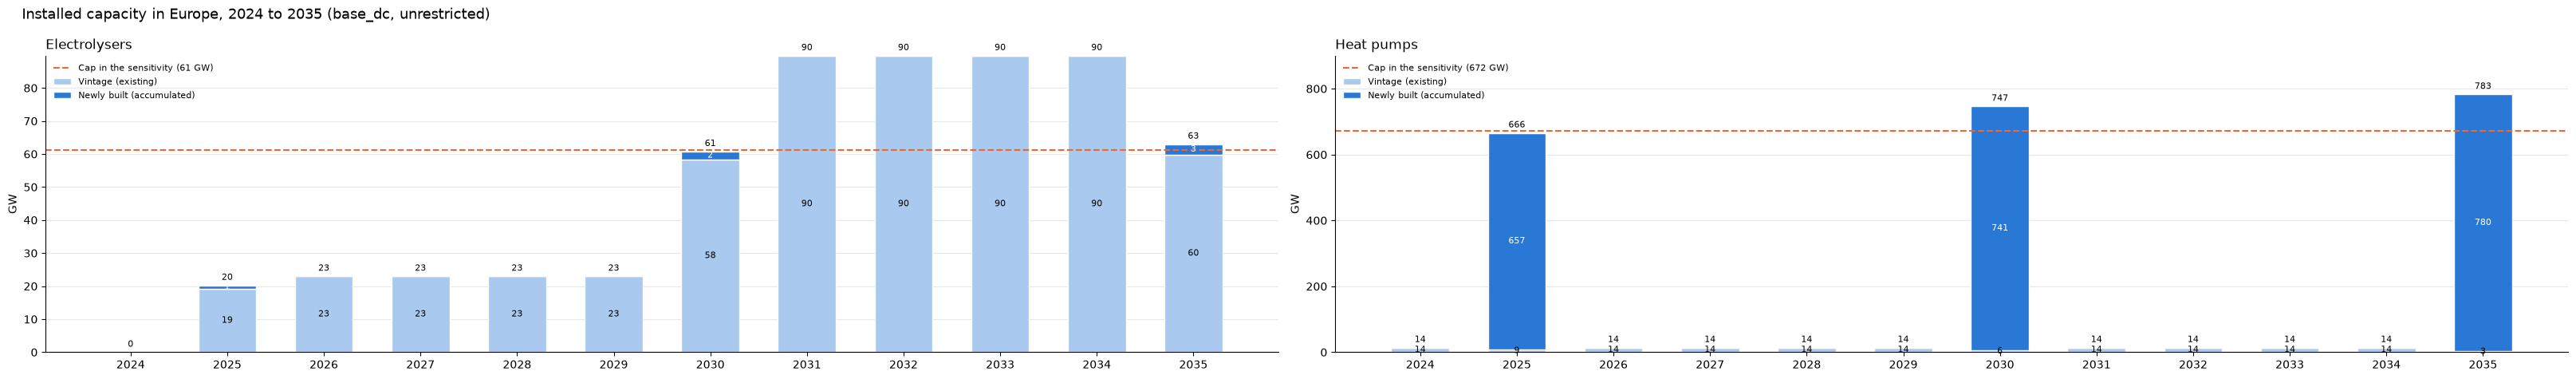

In [4]:
# 3.1 Installed capacity of electrolysers and heat pumps in Europe per year: vintage and newly built (GW), with the cap of the sensitivity
TS_FIRST_YEAR, LAST_YEAR = "2024", "2035"                                   # FIRST_YEAR of section 2 stays 2025: it defines the cap
def model_var_all_years(name, column):
    """Like model_var of section 2 but for every solved year up to LAST_YEAR (MW per region, technology group and year)."""
    t = container[name].records.rename(columns={container[name].records.columns[0]: "Year", container[name].records.columns[1]: "Area",
                                               container[name].records.columns[2]: "Generation"})
    t = t.assign(Year=t["Year"].astype(str), Region=t["Area"].map(area_region), Tech=t["Generation"].map(p2x_group))
    t = t.loc[t["Tech"].isin(["ELECTROLYZER", "HEATPUMP"]) & t["Region"].notna() & t["Year"].astype(int).between(int(TS_FIRST_YEAR), int(LAST_YEAR))]
    return t.groupby(["Tech", "Year"])[column].sum()

vintage_ts = model_var_all_years("GKFX", "value").sub(model_var_all_years("VDECOM_EXO_ACCUM", "level"), fill_value=0).clip(lower=0) / 1e3
new_ts = model_var_all_years("VGKNACCUMNET", "level") / 1e3
ts = pd.concat({"Vintage": vintage_ts, "New": new_ts}, axis=1).fillna(0)
ts["Total"] = ts["Vintage"] + ts["New"]
modelled_years = sorted(new_ts.index.get_level_values("Year").unique(), key=int)        # years the model solves (investments exist only there)
ts_years = [y for y in [TS_FIRST_YEAR] + modelled_years if y in set(ts.index.get_level_values("Year"))]
ts = ts.loc[ts.index.get_level_values("Year").isin(ts_years)]              # drop the years in between: GKFX exists for them, the model does not solve them
cap_line = {"ELECTROLYZER": pd.Series(np.nan, index=ts_years),                                        # no limit on the total (exogenous input is scaled instead, section 2.0)
            "HEATPUMP": hp_cap.sum().reindex(ts_years) / 1e3}                                         # GW, year-dependent bound of section 2.1 (NaN in 2024)
# 2024 is not a simulated year (Y = 2025, 2030, 2035): it only has the exogenous capacity (GKFX), i.e. the stock before any model investment.
# Warn if a year has no capacity at all, so that a missing year is not mistaken for zero capacity.
for tech in TECH_TITLE:
    missing = [y for y in ts_years if ts.xs(tech, level="Tech").reindex([y])["Total"].fillna(0).iloc[0] == 0]
    if missing: print(f"Note: no {tech} capacity in {', '.join(missing)} (none in the input data for that year)")
display(ts.unstack("Tech").reindex(ts_years).round(2))
print("Bound on the total (GW):", {t: c.round(1).to_dict() for t, c in cap_line.items()})

fig, axes = plt.subplots(1, 2, figsize=(max(11, 2.2 * len(ts_years) + 6), 4.8))
for ax, (tech, title) in zip(axes, TECH_TITLE.items()):
    d = ts.xs(tech, level="Tech").reindex(ts_years).fillna(0)
    x = np.arange(len(ts_years))
    ax.bar(x, d["Vintage"], 0.6, color="#a9c9ee", edgecolor="#fcfcfb", label="Vintage (existing)")
    ax.bar(x, d["New"], 0.6, bottom=d["Vintage"], color="#2a78d6", edgecolor="#fcfcfb", label="Newly built (accumulated)")
    for xi, v, n in zip(x, d["Vintage"], d["New"]):
        if v > 0.05 * d.sum(axis=1).max(): ax.text(xi, v / 2, f"{v:,.0f}", ha="center", va="center", fontsize=8)          # inner labels only on segments that are large enough
        if n > 0.05 * d.sum(axis=1).max(): ax.text(xi, v + n / 2, f"{n:,.0f}", ha="center", va="center", fontsize=8, color="white")
        ax.annotate(f"{v + n:,.0f}", (xi, v + n), ha="center", va="bottom", fontsize=8, xytext=(0, 3), textcoords="offset points")
    cl = cap_line[tech]
    if cl.notna().sum() == 0:
        pass                                                                   # no limit to draw for this technology
    elif cl.nunique() <= 1:
        ax.axhline(cl.dropna().iloc[0], color="#eb6834", linestyle="--", linewidth=1.5, label=f"Limit in the sensitivity ({cl.dropna().iloc[0]:,.0f} GW)")
    else:
        ax.plot(x, cl.values, color="#eb6834", linestyle="--", marker="D", linewidth=1.2, label="Limit in the sensitivity (per year)")
        for xi, v in zip(x, cl.values):
            if v == v: ax.annotate(f"{v:,.0f}", (xi, v), ha="left", va="bottom", fontsize=8, color="#c2410c", xytext=(6, 2), textcoords="offset points", bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    ax.set_xticks(x); ax.set_xticklabels(ts_years); ax.margins(y=0.15)
    ax.set_title(title, loc="left"); ax.set_ylabel("GW"); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
    ax.legend(frameon=False, loc="upper left", fontsize=8)
fig.suptitle(f"Installed capacity in Europe, {ts_years[0]} to {ts_years[-1]} ({RUN_FOLDER}, unrestricted)", x=0.01, ha="left", fontsize=13)
plt.tight_layout(); plt.show()

## 4. Effect of the cap on the electricity used by heat pumps and electrolysers: base_nodc vs sen_sc_base_nodc
Change in the annual electricity consumption (TWh) of heat pumps and electrolysers when the cap of section 2 is applied, in the runs without data centres (`sen_sc_base_nodc` minus `base_nodc`, fullweek results).
- **Heat pumps**: electricity consumed by the generators `GNR_HP_*` (`F_CONS_YCRA`, fuel `ELECTRIC`). Electric boilers, which are not capped, are not included.
- **Electrolysers**: electricity consumed by the generators `GNR_ELYS*` (`F_CONS_YCRA`), which equals the category `ENDO_H2` of `EL_DEMAND_YCR`.
- The results are read directly from the GDX files; `sen_sc_base_nodc` writes `MainResults.gdx`, `base_nodc` writes `MainResults_fullweek.gdx`.

base_nodc               sen_sc_base_nodc               Change (TWh)  \
     Heat pumps Electrolysers       Heat pumps Electrolysers   Heat pumps   
Year                                                                        
2025      846.5         107.8            846.5         107.8         -0.0   
2030      891.0         262.9            880.6         260.2        -10.4   
2035      900.1         279.0            875.6         260.7        -24.6   

                   Change (%)                
     Electrolysers Heat pumps Electrolysers  
Year                                         
2025          -0.0       -0.0          -0.0  
2030          -2.7       -1.2          -1.0  
2035         -18.3       -2.7          -6.6

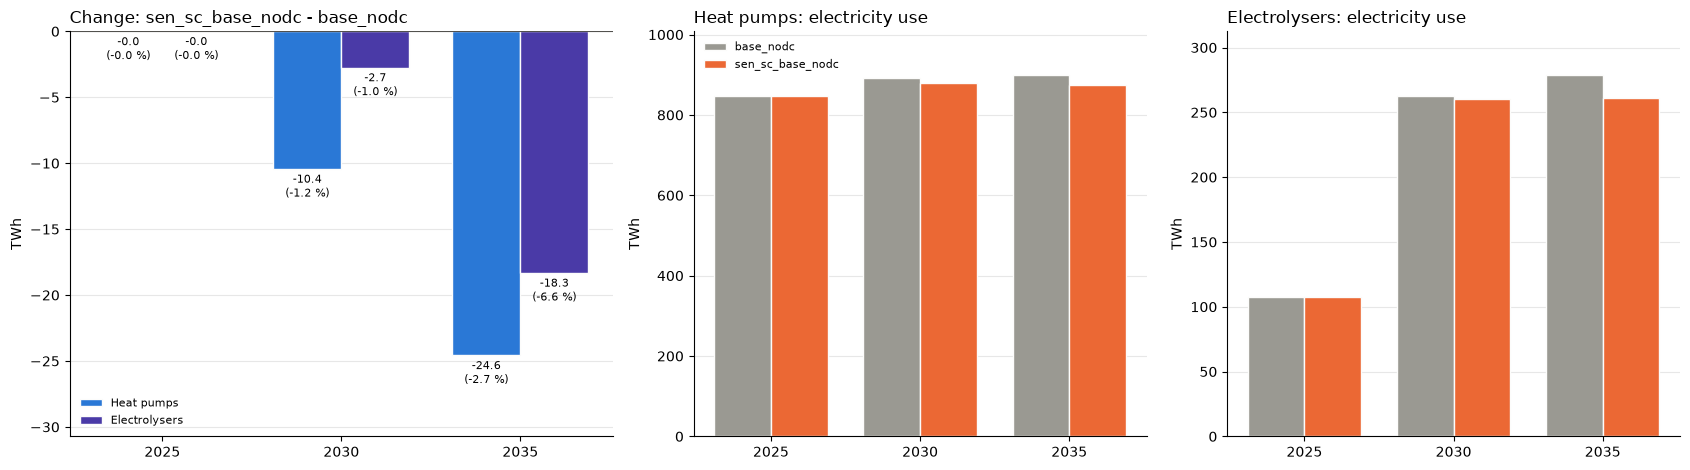

In [5]:
# 4. Electricity used by heat pumps and electrolysers: base_nodc vs sen_sc_base_nodc (TWh)
NODC_RUNS = {"base_nodc": Path.cwd() / "base_nodc" / "model" / "MainResults_fullweek.gdx",
             "sen_sc_base_nodc": Path.cwd() / "sen_sc_base_nodc" / "model" / "MainResults.gdx"}
NODC_REFERENCE = "base_nodc"
P2X_PREFIX = {"Heat pumps": "GNR_HP_", "Electrolysers": "GNR_ELYS"}
RUN_COLORS = {"base_nodc": "#9a9992", "sen_sc_base_nodc": "#eb6834"}

def p2x_electricity(path):
    """Annual electricity consumption (TWh) of heat pumps and electrolysers per year, from F_CONS_YCRA of a MainResults GDX."""
    c = gt.Container()
    c.read(str(path), symbols=["F_CONS_YCRA"])
    t = c["F_CONS_YCRA"].records
    t = t.loc[t["FFF"].astype(str).eq("ELECTRIC")].assign(Year=t["Y"].astype(str))
    return pd.DataFrame({name: t.loc[t["G"].astype(str).str.upper().str.startswith(prefix)].groupby("Year")["value"].sum()
                         for name, prefix in P2X_PREFIX.items()}).fillna(0).sort_index()

use = {run: p2x_electricity(path) for run, path in NODC_RUNS.items()}
other = [r for r in NODC_RUNS if r != NODC_REFERENCE][0]
change = use[other] - use[NODC_REFERENCE]
change_pct = change / use[NODC_REFERENCE].replace(0, np.nan) * 100

table = pd.concat({**{r: use[r] for r in NODC_RUNS}, "Change (TWh)": change, "Change (%)": change_pct}, axis=1)
display(table.round(1))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.2, 1, 1]})
years = list(change.index); x = np.arange(len(years)); w = 0.38
ax = axes[0]
for k, tech in enumerate(P2X_PREFIX):
    bars = ax.bar(x + (k - 0.5) * w, change[tech], w, color=["#2a78d6", "#4a3aa7"][k], edgecolor="#fcfcfb", label=tech)
    for bar, v, pct in zip(bars, change[tech], change_pct[tech]):
        ax.annotate(f"{v:+.1f}\n({pct:+.1f} %)", (bar.get_x() + bar.get_width() / 2, v), ha="center", va="bottom" if v >= 0 else "top",
                    fontsize=8, xytext=(0, 3 if v >= 0 else -3), textcoords="offset points")
ax.axhline(0, color="#52514e", linewidth=0.8); ax.set_xticks(x); ax.set_xticklabels(years); ax.margins(y=0.25)
ax.set_title(f"Change: {other} - {NODC_REFERENCE}", loc="left"); ax.set_ylabel("TWh"); ax.legend(frameon=False, loc="best", fontsize=8)
for ax, tech in zip(axes[1:], P2X_PREFIX):
    for k, run in enumerate(NODC_RUNS):
        ax.bar(x + (k - 0.5) * w, use[run][tech], w, color=RUN_COLORS[run], edgecolor="#fcfcfb", label=run)
    ax.set_xticks(x); ax.set_xticklabels(years); ax.margins(y=0.12)
    ax.set_title(f"{tech}: electricity use", loc="left"); ax.set_ylabel("TWh")
axes[1].legend(frameon=False, loc="upper left", fontsize=8)
for ax in axes:
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

## 5. Exogenous and endogenous capacity of electrolysers and heat pumps in base_nodc
Installed capacity in Europe (all regions) per modelled year in `base_nodc` (fullweek), from the raw model variables of `all_endofmodel_fullweek.gdx` (GW, model units: electrolysers as electricity input, heat pumps as the capacity that the model equations use):
- **Exogenous** = `GKFX` (capacity given as input data) minus `VDECOM_EXO_ACCUM` (accumulated decommissioning of that capacity). `GKFX` also contains planned build-out, so exogenous capacity can grow between years.
- **Endogenous** = `VGKNACCUMNET`, the capacity the model invests in, accumulated up to the year.
- Exogenous + endogenous is the quantity limited by `TECHGROUPKPOT`. The table also gives the gross exogenous capacity and the decommissioning.

Electrolysers  Heat pumps
Year                                                   
2025 Exogenous, gross (GKFX)          23.02       14.25
     Decommissioned                    3.80        5.31
     Exogenous, net                   19.22        8.94
     Endogenous (new)                  1.03      657.08
     Total                            20.25      666.02
2030 Exogenous, gross (GKFX)          89.81       14.23
     Decommissioned                   31.17        8.27
     Exogenous, net                   58.64        5.95
     Endogenous (new)                  2.58      741.20
     Total                            61.21      747.15
2035 Exogenous, gross (GKFX)          89.81       14.20
     Decommissioned                   27.95       11.02
     Exogenous, net                   61.85        3.18
     Endogenous (new)                  3.85      780.94
     Total                            65.71      784.11

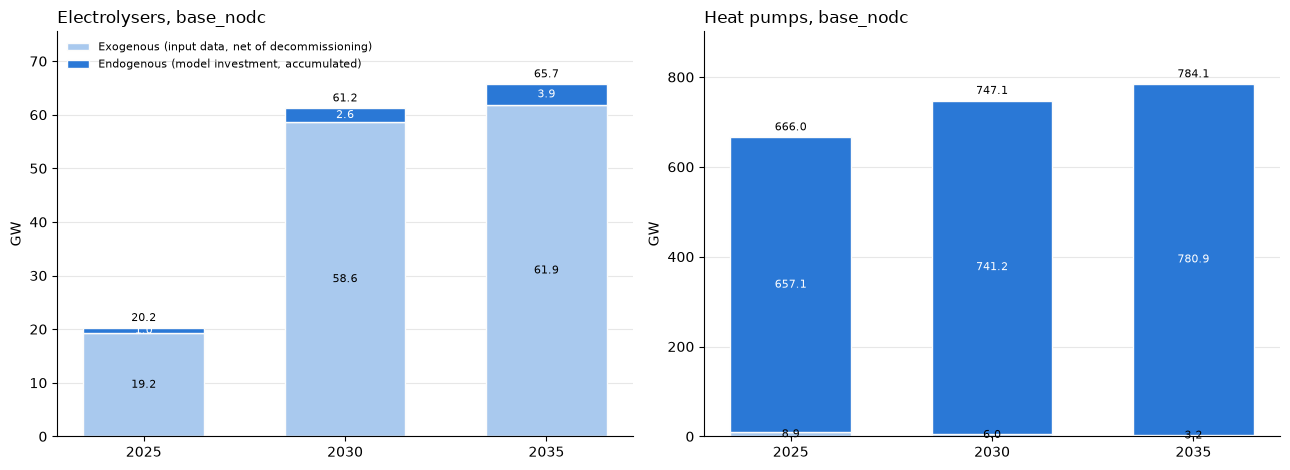

In [11]:
# 5. Exogenous and endogenous capacity of electrolysers and heat pumps per modelled year, base_nodc (GW)
NODC_FOLDER = "base_nodc"
NODC_GDX = Path.cwd() / NODC_FOLDER / "model" / "all_endofmodel_fullweek.gdx"
nodc_container = gt.Container()
nodc_container.read(str(NODC_GDX), symbols=["GKFX", "VDECOM_EXO_ACCUM", "VGKNACCUMNET"])
NODC_TECH = {"Electrolysers": "GNR_ELYS", "Heat pumps": "GNR_HP_"}          # generator-name prefix of each technology

def nodc_capacity(name, column):
    """Total of a raw model variable over all regions, per technology and year (GW). The first three columns are year, area and generator."""
    r = nodc_container[name].records
    r = r.rename(columns={r.columns[0]: "Year", r.columns[1]: "Area", r.columns[2]: "Generation"}).assign(Year=lambda d: d["Year"].astype(str))
    g = r["Generation"].astype(str).str.upper()
    return pd.DataFrame({tech: r.loc[g.str.startswith(prefix)].groupby("Year")[column].sum() for tech, prefix in NODC_TECH.items()}) / 1e3

gross = nodc_capacity("GKFX", "value")                                   # exogenous capacity as given (all years of the input data)
decom_n = nodc_capacity("VDECOM_EXO_ACCUM", "level")                     # only the modelled years
endo_n = nodc_capacity("VGKNACCUMNET", "level")
model_years = sorted(endo_n.index, key=int)                              # modelled years
exo_n = (gross.reindex(model_years).fillna(0) - decom_n.reindex(model_years).fillna(0)).clip(lower=0)
endo_n = endo_n.reindex(model_years).fillna(0)

cap_nodc = pd.concat({"Exogenous, gross (GKFX)": gross.reindex(model_years).fillna(0), "Decommissioned": decom_n.reindex(model_years).fillna(0),
                      "Exogenous, net": exo_n, "Endogenous (new)": endo_n, "Total": exo_n + endo_n}, axis=0).swaplevel().sort_index(level=0, sort_remaining=False)
display(cap_nodc.round(2))

fig, axes = plt.subplots(1, len(NODC_TECH), figsize=(6.5 * len(NODC_TECH), 4.8))
x = np.arange(len(model_years))
for ax, tech in zip(np.atleast_1d(axes), NODC_TECH):
    ax.bar(x, exo_n[tech], 0.6, color="#a9c9ee", edgecolor="#fcfcfb", label="Exogenous (input data, net of decommissioning)")
    ax.bar(x, endo_n[tech], 0.6, bottom=exo_n[tech], color="#2a78d6", edgecolor="#fcfcfb", label="Endogenous (model investment, accumulated)")
    for xi, e, n in zip(x, exo_n[tech], endo_n[tech]):
        if e > 0: ax.text(xi, e / 2, f"{e:,.1f}", ha="center", va="center", fontsize=8)
        if n > 0: ax.text(xi, e + n / 2, f"{n:,.1f}", ha="center", va="center", fontsize=8, color="white")
        ax.annotate(f"{e + n:,.1f}", (xi, e + n), ha="center", va="bottom", fontsize=8, xytext=(0, 3), textcoords="offset points")
    ax.set_xticks(x); ax.set_xticklabels(model_years); ax.margins(y=0.15)
    ax.set_title(f"{tech}, {NODC_FOLDER}", loc="left"); ax.set_ylabel("GW")
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
np.atleast_1d(axes)[0].legend(frameon=False, loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

### 5.1 Electrolysers in base_nodc: exogenous, decommissioned and new capacity
Uses the results of section 5 (run it first). Per modelled year, in GW of electricity input:
- **Exogenous, kept** = `GKFX` minus `VDECOM_EXO_ACCUM`: the planned capacity of `HYDROGEN_GKFX.inc` that the model keeps.
- **Exogenous, decommissioned** = `VDECOM_EXO_ACCUM`: planned capacity that the model retires (economic decommissioning, `ECONOMIC_DECOM_EXO_G`), because keeping it only costs fixed O&M. Hatched.
- **New (endogenous)** = `VGKNACCUMNET`: capacity the model invests in, accumulated up to the year.
The full bar (kept + decommissioned) is the gross exogenous capacity `GKFX`, i.e. what the input data prescribes.

,"Exogenous, gross (GKFX)",Decommissioned,"Exogenous, kept",New (endogenous),Total in operation,Decommissioned (% of gross exogenous)
Year,,,,,,
2025,23.02,3.80,19.22,1.03,20.25,16.50
2030,89.81,31.17,58.64,2.58,61.21,34.71
2035,89.81,27.95,61.85,3.85,65.71,31.12


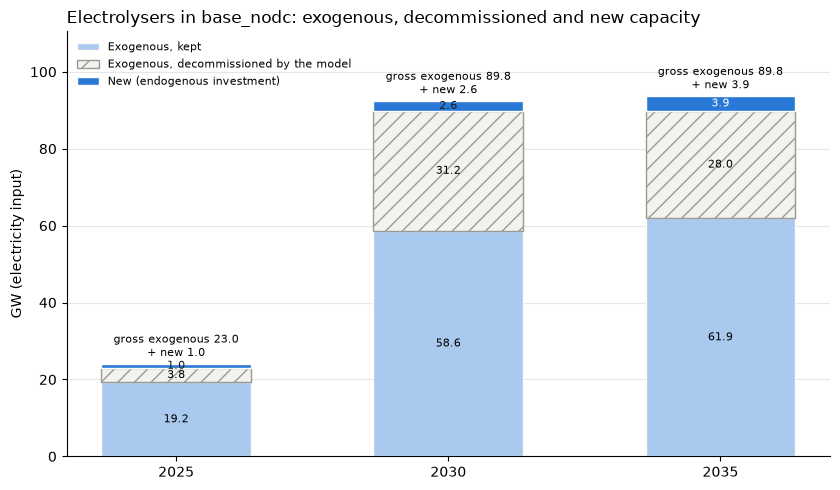

In [12]:
# 5.1 Electrolysers in base_nodc: exogenous (kept and decommissioned) and new capacity per modelled year (GW)
elys = pd.DataFrame({"Exogenous, gross (GKFX)": gross["Electrolysers"].reindex(model_years).fillna(0),
                     "Decommissioned": decom_n["Electrolysers"].reindex(model_years).fillna(0),
                     "New (endogenous)": endo_n["Electrolysers"]})
elys["Exogenous, kept"] = (elys["Exogenous, gross (GKFX)"] - elys["Decommissioned"]).clip(lower=0)
elys["Decommissioned (% of gross exogenous)"] = elys["Decommissioned"] / elys["Exogenous, gross (GKFX)"].replace(0, np.nan) * 100
elys["Total in operation"] = elys["Exogenous, kept"] + elys["New (endogenous)"]
display(elys[["Exogenous, gross (GKFX)", "Decommissioned", "Exogenous, kept", "New (endogenous)", "Total in operation",
              "Decommissioned (% of gross exogenous)"]].round(2))

fig, ax = plt.subplots(figsize=(8.5, 5))
x = np.arange(len(model_years))
kept, dec, new_ = elys["Exogenous, kept"], elys["Decommissioned"], elys["New (endogenous)"]
ax.bar(x, kept, 0.55, color="#a9c9ee", edgecolor="#fcfcfb", label="Exogenous, kept")
ax.bar(x, dec, 0.55, bottom=kept, color="#f2f2ef", edgecolor="#9a9992", hatch="//", label="Exogenous, decommissioned by the model")
ax.bar(x, new_, 0.55, bottom=kept + dec, color="#2a78d6", edgecolor="#fcfcfb", label="New (endogenous investment)")
for xi, k, d, n in zip(x, kept, dec, new_):
    if k > 0: ax.text(xi, k / 2, f"{k:,.1f}", ha="center", va="center", fontsize=8)
    if d > 0: ax.text(xi, k + d / 2, f"{d:,.1f}", ha="center", va="center", fontsize=8)
    ax.text(xi, k + d + n / 2, f"{n:,.1f}", ha="center", va="center", fontsize=8, color="white" if n > 3 else "#1a1a1a") if n > 0 else None
    ax.annotate(f"gross exogenous {k + d:,.1f}\n+ new {n:,.1f}", (xi, k + d + n), ha="center", va="bottom", fontsize=8, xytext=(0, 3), textcoords="offset points")
ax.set_xticks(x); ax.set_xticklabels(model_years); ax.margins(y=0.18)
ax.set_title("Electrolysers in base_nodc: exogenous, decommissioned and new capacity", loc="left"); ax.set_ylabel("GW (electricity input)")
ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
for side in ("top", "right"): ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()